# Clickbait transfer: Webis-Clickbait-17 → title interest

**External data:** Webis Clickbait Corpus 2017 ([Zenodo 5530410](https://zenodo.org/record/5530410), **CC BY 4.0**;
Potthast et al., 2018a). It contains about 41,000 tweets from news publishers. Five people rated each tweet on a
4-point scale (0, ⅓, ⅔, 1 = not clickbait → heavy clickbait), and `truthMean` is the average of the five ratings.
Only the JSONL files (posts and labels) were downloaded, with `fetch_webis.py`; the images were skipped. The files
are stored in `../external_data/webis_clickbait17/`.

**Why this dataset:** clickbait titles try to create curiosity, for example with a curiosity gap or with
exaggeration. These traits may also make a title look interesting. Webis is large and carefully labelled, so it
is suitable for training a good clickbait model. The question is then whether the clickbait score helps to
predict interest. The Webis model
is only used as a fixed feature extractor, like a pretrained encoder. The interest model itself is trained only
on `train.csv`.

**Sections:** 1 load the data → 2 analyse the clickbait corpus → 3 train clickbait models (TF-IDF ridge,
embeddings ridge, MLP) → 4 score the 150 competition titles → 5 test whether clickbait predicts interest (same 5×10 CV as
`baseline.ipynb`) → 6 submission.

In [1]:
import json, random, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import pearsonr, spearmanr
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, roc_auc_score
from sklearn.model_selection import RepeatedKFold

SEED = 42
random.seed(SEED); np.random.seed(SEED)

WEBIS = Path("../external_data/webis_clickbait17")
CACHE = Path("features"); CACHE.mkdir(exist_ok=True)

def load_split(folder):
    """Load one Webis-Clickbait-17 release: join the posts (instances.jsonl) with the labels
    (truth.jsonl) by id. postText is a list of strings, so it is joined into one 'post' string.
    truthMean = average clickbait rating of 5 annotators (0 = not clickbait, 1 = heavy clickbait).
    """
    inst = pd.read_json(WEBIS / folder / "instances.jsonl", lines=True, dtype={"id": str})
    truth = pd.read_json(WEBIS / folder / "truth.jsonl", lines=True, dtype={"id": str})
    df = inst[["id", "postText", "targetTitle"]].merge(truth, on="id")
    df["post"] = df["postText"].apply(lambda x: " ".join(x) if isinstance(x, list) else str(x)).str.strip()
    df["split"] = folder
    return df.drop(columns="postText")

wb = pd.concat([load_split(f) for f in
                ["clickbait17-train-170331", "clickbait17-train-170630", "clickbait17-test-170720"]], ignore_index=True)
print(wb.groupby("split").size())
print("duplicate ids:", wb["id"].duplicated().sum())
wb = wb.drop_duplicates("id").reset_index(drop=True)
wb = wb[wb["post"].str.len() > 0].reset_index(drop=True)
# official split: both train releases -> train, 170720 -> held-out test
wb["is_test"] = wb["split"].eq("clickbait17-test-170720")
print(wb.shape, "| train", (~wb.is_test).sum(), "| test", wb.is_test.sum())
wb[["post", "truthMean", "truthJudgments", "truthClass"]].head()

split
clickbait17-test-170720     18979
clickbait17-train-170331     2459
clickbait17-train-170630    19538
dtype: int64
duplicate ids: 0
(40856, 10) | train 21943 | test 18913


,post,truthMean,truthJudgments,truthClass
0,Apple's iOS 9 'App thinning' feature will give...,0.200000,"[0.0, 0.666667, 0.0, 0.333333, 0.0]",no-clickbait
1,RT @kenbrown12: Emerging market investors are ...,0.133333,"[0.666667, 0.0, 0.0, 0.0, 0.0]",no-clickbait
2,U.S. Soccer should start answering tough quest...,0.533333,"[0.333333, 0.666667, 1.0, 0.0, 0.666667]",clickbait
3,How theme parks like Disney World left the mid...,0.466667,"[1.0, 0.0, 0.333333, 0.333333, 0.666667]",no-clickbait
4,Could light bulbs hurt your health? One compan...,0.666667,"[1.0, 0.333333, 0.666667, 0.333333, 1.0]",clickbait


## 2. Analyse the clickbait corpus

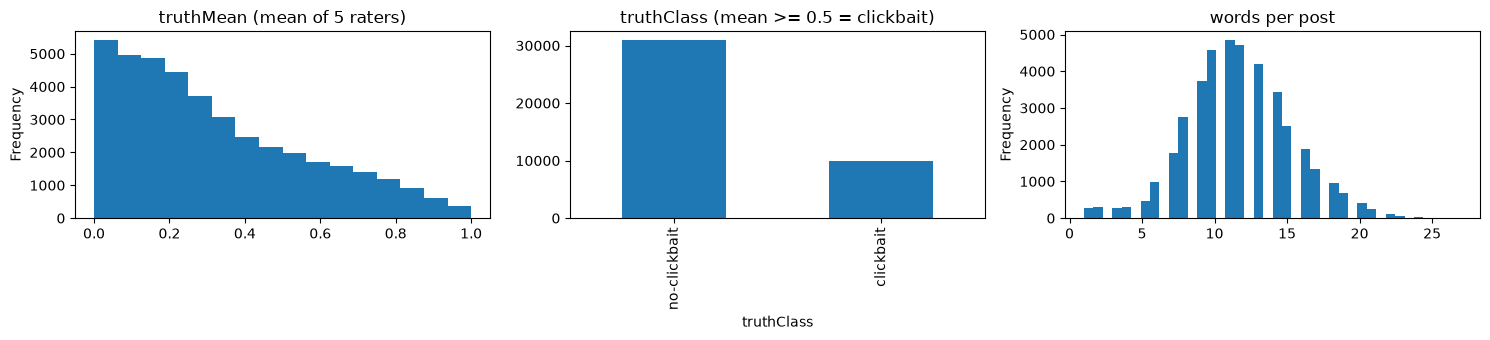

truthClass
no-clickbait    0.757
clickbait       0.243
Name: proportion, dtype: float64


In [2]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
wb["truthMean"].plot.hist(bins=16, ax=ax[0], title="truthMean (mean of 5 raters)")
wb["truthClass"].value_counts().plot.bar(ax=ax[1], title="truthClass (mean >= 0.5 = clickbait)")
wb["post"].str.split().str.len().clip(upper=40).plot.hist(bins=40, ax=ax[2], title="words per post")
plt.tight_layout(); plt.show()
print(wb["truthClass"].value_counts(normalize=True).round(3))

### What makes a post clickbait? Surface cues

Before any model is trained, some simple surface cues are checked. Each cue comes from earlier research on
clickbait headlines:

| Cue in the code | What it checks | Source |
|---|---|---|
| `n_words` | length of the post in words | headline length (Chakraborty et al., 2016, Sec. 3.1) |
| `question`, `exclaim` | contains "?" or "!" | unusual punctuation such as "!?" and "!!!" (Chakraborty et al., 2016, Sec. 3.2) |
| `digits_start` | starts with a number, e.g. "26 haunting images…" | "cardinal numbers in the beginning of the headline" (Chakraborty et al., 2016, Sec. 4.1) |
| `digits` | contains any number | a wider version of the cue above, not taken from a paper |
| `you` | "you", "your", "you're" | the reader is addressed in the second person (Chakraborty et al., 2016, Sec. 3.3) |
| `this_these` | "this", "these", "here's", "here is" | forward-reference: the title points to something it does not name yet (Blom & Hansen, 2015); determiners such as "these" (Chakraborty et al., 2016, Sec. 3.3); examples like "This actor fell…" (Potthast et al., 2018b) |
| `superlative` | "best", "worst", "amazing", "shocking", … | hyperbolic words (Chakraborty et al., 2016, Sec. 3.2). A short word list replaces the sentiment tool used in that paper. |
| `caps_words` | words in CAPITAL letters | an extra cue, not taken from a paper |

Chakraborty et al. studied news headlines, but the Webis posts are tweets. So the findings from that paper are not
simply copied. Each cue is measured again on Webis with the Spearman correlation to `truthMean`.

/var/folders/7s/rgb20vpx2f9_ly3fy0b4x0pw0000gn/T/ipykernel_94480/2940639769.py:15: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "you": low.str.contains(r"\b(you|your|you're)\b").astype(int),
/var/folders/7s/rgb20vpx2f9_ly3fy0b4x0pw0000gn/T/ipykernel_94480/2940639769.py:16: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "this_these": low.str.contains(r"\b(this|these|here's|here is)\b").astype(int),
/var/folders/7s/rgb20vpx2f9_ly3fy0b4x0pw0000gn/T/ipykernel_94480/2940639769.py:18: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "superlative": low.str.contains(r"\b(best|worst|most|ever|amazing|incredible|shocking)\b").astype(int),


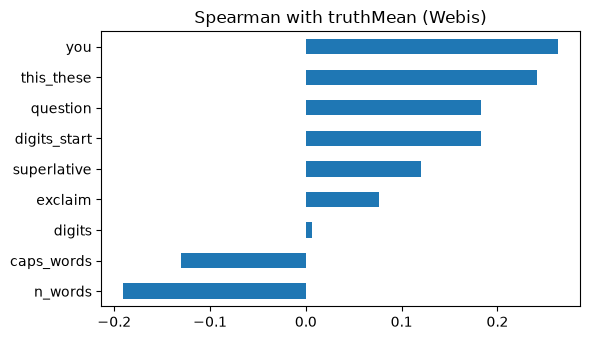

n_words        -0.191
caps_words     -0.130
digits          0.007
exclaim         0.077
superlative     0.121
digits_start    0.183
question        0.183
this_these      0.241
you             0.263
dtype: float64

In [3]:
def cues(text):
    """Hand-made clickbait cues per post: word count, '?', '!', starts with a digit ('10 reasons...'),
    any digit, 'you', 'this/these/here's' (forward references), ALL-CAPS words, superlatives.
    Used to see which cues correlate with the clickbait score.
    """
    t = pd.Series(text).fillna("")
    w = t.str.split()
    low = t.str.lower()
    return pd.DataFrame({
        "n_words": w.str.len(),
        "question": t.str.contains(r"\?").astype(int),
        "exclaim": t.str.contains("!").astype(int),
        "digits_start": t.str.match(r"^\d").astype(int),
        "digits": t.str.contains(r"\d").astype(int),
        "you": low.str.contains(r"\b(you|your|you're)\b").astype(int),
        "this_these": low.str.contains(r"\b(this|these|here's|here is)\b").astype(int),
        "caps_words": w.apply(lambda x: sum(s.isupper() and len(s) > 1 for s in x)),
        "superlative": low.str.contains(r"\b(best|worst|most|ever|amazing|incredible|shocking)\b").astype(int),
    })

C_wb = cues(wb["post"].values)
corr = C_wb.apply(lambda c: spearmanr(c, wb.truthMean)[0]).sort_values()
corr.plot.barh(figsize=(6, 3.5), title="Spearman with truthMean (Webis)"); plt.tight_layout(); plt.show()
corr.round(3)

**What the output shows.** The cues from the literature work on Webis too. Addressing the reader ("you", +0.26),
forward-reference words ("this", "these", +0.24), questions (+0.18) and a number at the start (+0.18) all go
together with higher clickbait scores. One result is different from Chakraborty et al.: in the headline data of that study,
clickbait headlines were *longer*, but in Webis, longer posts are *less* clickbait-like (−0.19). The extra cue
`caps_words` is also negative (−0.13). Most capital words in news tweets are short names such as NASA or FBI,
not shouting.

In [4]:
# most clickbait-y vs least clickbait-y words (TF-IDF ridge coefficients on the Webis train split)
tf = TfidfVectorizer(ngram_range=(1, 2), min_df=5, sublinear_tf=True)
Xtf = tf.fit_transform(wb["post"])
tr, te = ~wb.is_test.values, wb.is_test.values
r_tf = Ridge(alpha=3).fit(Xtf[tr], wb.truthMean[tr])
coef = pd.Series(r_tf.coef_, index=tf.get_feature_names_out()).sort_values()
print("least clickbait:", ", ".join(coef.index[:20]))
print("most clickbait :", ", ".join(coef.index[-20:][::-1]))

least clickbait: to, says, in, trump, after, at, on, as, for, million, ban, tells, of, attack, dies at, per, over, reportedly, despite, wins
most clickbait : this, why, these, things, you, what, how, your, ways, here, oh, quiz, ways to, weird, foods, stories, how to, alas, everyone, someone


In [5]:
for q, g in wb.sort_values("truthMean").groupby(pd.qcut(wb.truthMean.rank(method="first"), 3, labels=["low", "mid", "high"])):
    print(f"--- {q} clickbait ---")
    for t, s in g.sample(4, random_state=SEED)[["post", "truthMean"]].values:
        print(f"{s:.2f}  {t[:110]}")

--- low clickbait ---
0.07  Israel’s leader, facing conservatives, takes a harder stance on settlements
0.13  Debbie Reynolds, the Hollywood aristocrat who was a vitamin boost for the heart
0.07  Police arrest Thai activist for Facebook 'share' about new king
0.07  Hospitalizations from gunshot wounds cost $700 million a year in the US, a new study says
--- mid clickbait ---
0.27  The holiday shopping season is losing some of its power
0.33  Toni Erdmann review – talk about embarrassing parents…
0.27  Trampoline park injuries trigger hundreds of ambulance call-outs
0.27  Joan Baez tears into "future dictator" @realdonaldtrump in new "Nasty Man" song
--- high clickbait ---
0.60  The first pictures from NOAA's newest weather satellite are incredible
0.87  26 haunting images of ghost towns in America
0.67  Just an hour a day on social media can affect kids' happiness - and not in a good way
0.60  The first step to stopping negative thoughts is a surprising one: Don't try to stop them


## 3. Train clickbait models (Webis train → Webis test)

Target = `truthMean`. Metrics as in the Clickbait Challenge: MSE (lower better), Pearson r, and accuracy / AUC of
the clickbait class (mean ≥ 0.5). Three models: TF-IDF ridge, frozen mpnet embeddings + ridge, and a small MLP
(PyTorch) on the same embeddings.

In [6]:
def report(name, pred, y=wb.truthMean[te].values):
    """Score clickbait predictions on the held-out Webis test set.
    MSE and Pearson r on the 0-1 score; AUC and accuracy on the binary label (truthMean >= 0.5 = clickbait).
    """
    pred = np.clip(pred, 0, 1)
    out = dict(MSE=mean_squared_error(y, pred), pearson=pearsonr(y, pred)[0],
               AUC=roc_auc_score(y >= 0.5, pred), acc=((pred >= 0.5) == (y >= 0.5)).mean())
    print(f"{name:28s} " + "  ".join(f"{k} {v:.4f}" for k, v in out.items()))
    return out

wb_res = {}
wb_res["constant train mean"] = report("constant train mean", np.full(te.sum(), wb.truthMean[tr].mean()))
wb_res["TF-IDF ridge"] = report("TF-IDF ridge", r_tf.predict(Xtf[te]))

constant train mean          MSE 0.0743  pearson nan  AUC 0.5000  acc 0.7703
TF-IDF ridge                 MSE 0.0419  pearson 0.6792  AUC 0.8764  acc 0.8365


/var/folders/7s/rgb20vpx2f9_ly3fy0b4x0pw0000gn/T/ipykernel_94480/2357595749.py:6: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  out = dict(MSE=mean_squared_error(y, pred), pearson=pearsonr(y, pred)[0],


In [7]:
import torch
from transformers import AutoTokenizer, AutoModel

torch.manual_seed(SEED)
DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"
EMB_MODEL = "sentence-transformers/all-mpnet-base-v2"

def embed(texts, model_name=EMB_MODEL, batch_size=128, max_length=64):
    """Turn each text into one sentence-embedding vector (frozen pretrained transformer, no training).

    Steps per batch:
      1. tokenize: split text into word pieces, pad to equal length (attention_mask = 1 for real tokens, 0 for padding)
      2. run the encoder -> last_hidden_state: one vector per token, shape (batch, tokens, hidden)
      3. mean pooling: average the token vectors, ignoring padding -> one vector per text
      4. L2-normalise to length 1, so only the direction (meaning) matters
    Returns a numpy array of shape (len(texts), hidden_size), e.g. 768 for mpnet/BERT.
    """
    tok = AutoTokenizer.from_pretrained(model_name)
    enc = AutoModel.from_pretrained(model_name).to(DEVICE).eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            b = tok(list(texts[i:i + batch_size]), padding=True, truncation=True,
                    max_length=max_length, return_tensors="pt").to(DEVICE)
            h = enc(**b).last_hidden_state
            mask = b["attention_mask"].unsqueeze(-1).float()
            e = (h * mask).sum(1) / mask.sum(1)
            out.append(torch.nn.functional.normalize(e, dim=1).cpu().numpy())
    return np.vstack(out).astype(np.float32)

f_wb = CACHE / "webis_mpnet.npz"
ids_wb = wb["id"].values.astype(str)          # plain strings, so np.load works without pickle
cache = np.load(f_wb) if f_wb.exists() else None
if cache is not None and cache["ids"].shape == ids_wb.shape and (cache["ids"] == ids_wb).all():
    E_wb = cache["emb"]
else:
    E_wb = embed(wb["post"].values)
    np.savez(f_wb, emb=E_wb, ids=ids_wb)
print(E_wb.shape)

for a in (1, 10):
    r = Ridge(alpha=a).fit(E_wb[tr], wb.truthMean[tr])
    wb_res[f"mpnet ridge a={a}"] = report(f"mpnet ridge a={a}", r.predict(E_wb[te]))

/Users/home/workspace/School/ML/competition/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(40856, 768)
mpnet ridge a=1              MSE 0.0363  pearson 0.7276  AUC 0.8943  acc 0.8540
mpnet ridge a=10             MSE 0.0389  pearson 0.7070  AUC 0.8845  acc 0.8458


In [8]:
class TorchMLP:
    """One-hidden-layer neural network regressor (MSE loss, AdamW, fixed epochs, fixed seed).
    Here trained on ~19k Webis posts to predict the clickbait score from mpnet embeddings.
    """
    def __init__(self, hidden=256, dropout=0.3, wd=1e-2, epochs=10, lr=1e-3, batch=128, seed=SEED):
        """Store all hyper-parameters as attributes (self.hidden, self.dropout, ...)."""
        self.__dict__.update(locals()); del self.__dict__["self"]
    def fit(self, X, y):
        """Train the network on (y - mean) in shuffled mini-batches for a fixed number of epochs."""
        torch.manual_seed(self.seed)
        self.mu = float(np.mean(y))
        self.net = torch.nn.Sequential(torch.nn.Linear(X.shape[1], self.hidden), torch.nn.GELU(),
                                       torch.nn.Dropout(self.dropout), torch.nn.Linear(self.hidden, 1))
        opt = torch.optim.AdamW(self.net.parameters(), lr=self.lr, weight_decay=self.wd)
        Xt = torch.tensor(X, dtype=torch.float32); yt = torch.tensor(np.asarray(y) - self.mu, dtype=torch.float32)
        g = torch.Generator().manual_seed(self.seed)
        for _ in range(self.epochs):
            self.net.train()
            for idx in torch.randperm(len(Xt), generator=g).split(self.batch):
                opt.zero_grad()
                torch.nn.functional.mse_loss(self.net(Xt[idx]).squeeze(1), yt[idx]).backward()
                opt.step()
        return self
    def predict(self, X):
        """Predict in eval mode (dropout off, no gradients) and add the training mean back."""
        self.net.eval()
        with torch.no_grad():
            return self.net(torch.tensor(X, dtype=torch.float32)).squeeze(1).numpy() + self.mu

mlp_wb = TorchMLP().fit(E_wb[tr], wb.truthMean[tr].values)
wb_res["mpnet MLP"] = report("mpnet MLP", mlp_wb.predict(E_wb[te]))
pd.DataFrame(wb_res).T.round(4)

mpnet MLP                    MSE 0.0363  pearson 0.7228  AUC 0.8919  acc 0.8520


,MSE,pearson,AUC,acc
constant train mean,0.0743,NaN,0.5000,0.7703
TF-IDF ridge,0.0419,0.6792,0.8764,0.8365
mpnet ridge a=1,0.0363,0.7276,0.8943,0.8540
mpnet ridge a=10,0.0389,0.7070,0.8845,0.8458
mpnet MLP,0.0363,0.7228,0.8919,0.8520


For reference, the official results of the Clickbait Challenge 2017 used the same test set (Potthast et al.,
2018b, Table 3). The best team reached MSE 0.033, the next two teams reached 0.036, and the organisers' feature
baseline (Potthast et al., 2016, with ridge regression) reached 0.044. The organisers' constant baseline reached 0.0735,
which is very close to the 0.0743 here. The mpnet ridge model in this notebook (MSE 0.036) is therefore at the level of the second
and third teams. This comparison is only approximate: a few empty posts were removed here, and the smaller first training
release was also used for training.

Final clickbait scorers for transfer: refit ridge and MLP on **all** Webis rows (train + test).

In [9]:
cb_ridge = Ridge(alpha=10).fit(E_wb, wb.truthMean)
cb_mlp = TorchMLP().fit(E_wb, wb.truthMean.values)
cb_tfidf = Ridge(alpha=3).fit(Xtf, wb.truthMean)

## 4. Score the 150 competition titles

In this step, the clickbait models from Section 3 give every competition title a clickbait score. All 150
titles are scored: the 120 training titles and the 30 test titles. The test titles need a score too,
because the final model in Section 6 uses this score as an input. No interest labels are used here. The
clickbait models were trained only on the Webis data, so the models work like a fixed tool, in the same way as the
mpnet encoder.

The step adds three new columns to the `titles` table:

| Column | How it is calculated |
|---|---|
| `cb_ridge` | mpnet embedding of the title → ridge model |
| `cb_mlp` | mpnet embedding of the title → small neural network (MLP) |
| `cb_tfidf` | TF-IDF word features of the title → ridge model |

Each score is between 0 and 1. A score near 0 means that the title reads like normal news. A score near 1
means that it reads like strong clickbait. The table also gets the column `is_train`, which is `True` for the 120
titles that have an interest label.

The competition titles come from YouTube, Reddit, podcasts and news articles, but the Webis posts are news tweets. This
means the models are used on a different kind of text. The titles are embedded without the `domain:` prefix, to stay closer to
the style of Webis posts.

The cell prints two checks:
1. the average score for each source,
2. the four titles with the lowest `cb_ridge` score and the four with the highest.

In [10]:
train = pd.read_csv("data/train.csv"); test = pd.read_csv("data/test.csv"); sample = pd.read_csv("data/sample_submission.csv")
titles = pd.concat([train, test], ignore_index=True)
E_t = embed(titles["title"].values)
titles["cb_ridge"] = np.clip(cb_ridge.predict(E_t), 0, 1)
titles["cb_mlp"] = np.clip(cb_mlp.predict(E_t), 0, 1)
titles["cb_tfidf"] = np.clip(cb_tfidf.predict(tf.transform(titles["title"])), 0, 1)
titles["is_train"] = titles["interest"].notna()

print(titles.groupby("domain")[["cb_ridge", "cb_mlp", "cb_tfidf"]].mean().round(3))
print()
for _, r in titles.sort_values("cb_ridge").iloc[np.r_[0:4, -4:0]].iterrows():
    print(f"{r.cb_ridge:.2f}  [{r.domain}] {r.title[:90]}")

W1122 15:48:05.436000 94480 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 6930.89it/s]


         cb_ridge  cb_mlp  cb_tfidf
domain                             
article     0.194   0.169     0.264
podcast     0.434   0.445     0.382
reddit      0.486   0.520     0.460
youtube     0.470   0.491     0.373

0.03  [article] AMTRAK train strikes, kills man walking on tracks in Osceola County - WKMG
0.08  [article] Hammer attack outside Brooklyn Burger King leaves 2 men injured - ABC7 Eyewitness News
0.09  [youtube] Noah Kahan - Draw You Out (from The Hunger Games: Sunrise on the Reaping - The Album) (Lyr
0.09  [article] SBI agent shot while searching for man in Reidsville; suspect charged, officials say - WXI
0.71  [youtube] I Found EVERY SECRET at RON'S HOUSE in ANIMAL HOSPITAL!
0.71  [reddit] 2500 mile flight, 2 hour drive, 6 hour hike, and my wife is at rest.
0.72  [youtube] Playing Hide and Seek in Rivals..
0.79  [podcast] Do you nose who fibs about MUCUS?


**What the output shows.** News articles get the lowest scores (about 0.2). Reddit, YouTube and podcast
titles get about twice as much (0.4 to 0.5). The titles with the lowest scores are short, factual news reports,
for example *"AMTRAK train strikes, kills man walking on tracks…"* (0.03). The titles with the highest scores use
a curiosity gap or playful wording, for example *"Do you nose who fibs about MUCUS?"* (0.79). So the scores look
sensible for the competition titles, even though the models were trained on tweets.

At this point, the scores only show how much each title looks like clickbait. Interest has not been predicted
yet.
Section 5 tests whether these scores help to predict interest.

## 5. Does clickbait-ness predict interest? (train.csv only)

In [11]:
tr_t = titles[titles.is_train].reset_index(drop=True)
rows = []
for c in ["cb_ridge", "cb_mlp", "cb_tfidf"]:
    rows.append(dict(score=c, domain="all", n=len(tr_t), spearman=spearmanr(tr_t[c], tr_t.interest)[0]))
    for d, g in tr_t.groupby("domain"):
        rows.append(dict(score=c, domain=d, n=len(g), spearman=spearmanr(g[c], g.interest)[0]))
corr_t = pd.DataFrame(rows).pivot(index="score", columns="domain", values="spearman").round(3)
print("Spearman(clickbait score, interest) on 120 train titles; |r| < ~0.18 is not significant at n=120")
corr_t

Spearman(clickbait score, interest) on 120 train titles; |r| < ~0.18 is not significant at n=120


domain,all,article,podcast,reddit,youtube
score,,,,,
cb_mlp,-0.029,0.063,0.135,-0.139,0.058
cb_ridge,-0.042,-0.111,0.127,-0.085,-0.007
cb_tfidf,-0.150,0.099,-0.208,-0.261,-0.206


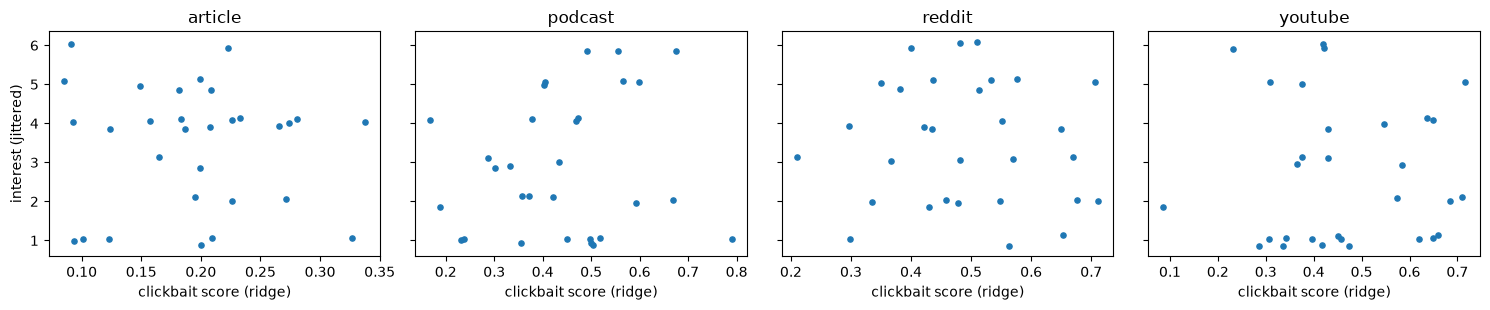

In [12]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for a, (d, g) in zip(ax, tr_t.groupby("domain")):
    a.scatter(g.cb_ridge, g.interest + np.random.default_rng(0).uniform(-.15, .15, len(g)), s=14)
    a.set_title(d); a.set_xlabel("clickbait score (ridge)")
ax[0].set_ylabel("interest (jittered)"); plt.tight_layout(); plt.show()

**What the plot shows.** Each panel shows one source, and each dot is one of the 120 training titles. The
x-axis is the clickbait score (`cb_ridge`, 0 to 1) and the y-axis is the interest label (1 to 6). A small random
shift (jitter) is added to the labels, so that titles with the same label do not hide each other.

If clickbait titles were more interesting, the dots would rise from left to right. In all four panels, the dots
form a flat cloud with no clear direction: titles with a high clickbait score get low and high interest labels
just as often as titles with a low score. The table above shows the same result in numbers. Most correlations
are close to 0 (between −0.26 and +0.14), and with only 120 titles, a correlation smaller than about ±0.18 can
easily happen by chance.

So clickbait style and interest are mostly unrelated in this data. Section 5 checks this with a model: adding
the clickbait scores does not lower the cross-validation error.

### Same CV as `baseline.ipynb` (5-fold × 10 repeats, MAE vs single-annotator labels)

Features: domain one-hots + clickbait scores (+ optionally the mpnet title embedding). Only the small interest
model is fit inside each fold; the clickbait scorers are frozen.

In [13]:
y = tr_t["interest"].values.astype(float)
cv = list(RepeatedKFold(n_splits=5, n_repeats=10, random_state=SEED).split(y))
results = {}

def evaluate(name, make_model, X):
    """Score one model with the shared repeated cross-validation (5 folds x 10 repeats = 50 splits).

    make_model: function that builds a NEW untrained model, e.g. lambda: Ridge(alpha=10).
                A fresh model per split guarantees nothing learned on one split leaks into another.
    X:          feature matrix for the 120 training titles (same row order as y).
    For every split: fit on ~96 titles, predict the ~24 held-out titles, clip to the valid range 1-6, compute MAE.
    Prints and stores mean +/- std of the 50 MAEs in `results[name]`.
    """
    maes = [mean_absolute_error(y[va], np.clip(make_model().fit(X[tr_], y[tr_]).predict(X[va]), 1, 6))
            for tr_, va in cv]
    results[name] = dict(mae=np.mean(maes), std=np.std(maes))
    print(f"{name:42s} MAE {np.mean(maes):.3f} ± {np.std(maes):.3f}")

class Const:
    """Baseline 'model' that ignores the features and always predicts one number (the training mean).
    Every real model has to beat this reference point.
    """
    # remember the mean of the training labels
    def fit(self, X, y): self.c = y.mean(); return self
    # same value for every title
    def predict(self, X): return np.full(len(X), self.c)

dom = pd.get_dummies(titles["domain"]).values.astype(float)
cb_cols = ["cb_ridge", "cb_mlp", "cb_tfidf"]
CB = titles[cb_cols].values
CB_z = (CB - CB.mean(0)) / CB.std(0)
E_dom = embed((titles["domain"] + ": " + titles["title"]).values)   # same text as baseline.ipynb
n = len(train)

X_dom = dom[:n]
X_cb = np.hstack([dom, CB_z])[:n]
X_cb1 = np.hstack([dom, CB_z[:, :1]])[:n]
X_emb = np.hstack([E_dom, dom])[:n]
X_emb_cb = np.hstack([E_dom, dom, CB_z * 0.3])[:n]

evaluate("constant mean", Const, X_dom)
evaluate("domain ridge", lambda: Ridge(alpha=10), X_dom)
for a in (3, 10, 30):
    evaluate(f"domain + clickbait(ridge) ridge a={a}", lambda a=a: Ridge(alpha=a), X_cb1)
    evaluate(f"domain + 3 clickbait scores ridge a={a}", lambda a=a: Ridge(alpha=a), X_cb)
evaluate("mpnet SVR C=0.3 (baseline best)", lambda: SVR(C=0.3, epsilon=0.5), X_emb)
evaluate("mpnet + clickbait SVR C=0.3", lambda: SVR(C=0.3, epsilon=0.5), X_emb_cb)
for a in (10, 30):
    evaluate(f"mpnet + clickbait ridge a={a}", lambda a=a: Ridge(alpha=a), X_emb_cb)
res = pd.DataFrame(results).T.sort_values("mae")
res.round(3)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 14263.17it/s]


constant mean                              MAE 1.495 ± 0.174
domain ridge                               MAE 1.478 ± 0.181
domain + clickbait(ridge) ridge a=3        MAE 1.494 ± 0.183
domain + 3 clickbait scores ridge a=3      MAE 1.475 ± 0.179
domain + clickbait(ridge) ridge a=10       MAE 1.492 ± 0.179
domain + 3 clickbait scores ridge a=10     MAE 1.473 ± 0.174
domain + clickbait(ridge) ridge a=30       MAE 1.490 ± 0.175
domain + 3 clickbait scores ridge a=30     MAE 1.477 ± 0.171
mpnet SVR C=0.3 (baseline best)            MAE 1.466 ± 0.178
mpnet + clickbait SVR C=0.3                MAE 1.468 ± 0.173
mpnet + clickbait ridge a=10               MAE 1.479 ± 0.178
mpnet + clickbait ridge a=30               MAE 1.478 ± 0.176


,mae,std
mpnet SVR C=0.3 (baseline best),1.466,0.178
mpnet + clickbait SVR C=0.3,1.468,0.173
domain + 3 clickbait scores ridge a=10,1.473,0.174
domain + 3 clickbait scores ridge a=3,1.475,0.179
domain + 3 clickbait scores ridge a=30,1.477,0.171
domain ridge,1.478,0.181
mpnet + clickbait ridge a=30,1.478,0.176
mpnet + clickbait ridge a=10,1.479,0.178
domain + clickbait(ridge) ridge a=30,1.490,0.175
domain + clickbait(ridge) ridge a=10,1.492,0.179


## 6. Submission

`submission_clickbait.csv` is written with the best cross-validation model that uses the clickbait features. The
model is trained on all 120 training titles. Its CV MAE (1.468) is better than the constant mean (1.495), but not
better than the mpnet SVR without clickbait features (1.466).

In [14]:
Xfull = {"domain + clickbait(ridge)": np.hstack([dom, CB_z[:, :1]]),
         "domain + 3 clickbait scores": np.hstack([dom, CB_z]),
         "mpnet + clickbait": np.hstack([E_dom, dom, CB_z * 0.3])}
cb_rows = [r for r in res.index if "clickbait" in r]
best = cb_rows[0]
key = next(k for k in Xfull if best.startswith(k))
model = SVR(C=0.3, epsilon=0.5) if "SVR" in best else Ridge(alpha=float(best.split("a=")[-1]))
pred = np.clip(model.fit(Xfull[key][:n], y).predict(Xfull[key][n:]), 1, 6)

sub = pd.DataFrame({"title_id": test["title_id"], "interest": pred.round(3)})
assert list(sub.columns) == list(sample.columns) and set(sub.title_id) == set(sample.title_id)
sub.to_csv("submission_clickbait.csv", index=False)
print("model:", best, "| CV MAE", round(results[best]["mae"], 3), "| vs constant", round(results["constant mean"]["mae"], 3))
print(sub["interest"].describe().round(2))

model: mpnet + clickbait SVR C=0.3 | CV MAE 1.468 | vs constant 1.495
count    30.00
mean      3.05
std       0.39
min       2.48
25%       2.69
50%       3.07
75%       3.43
max       3.51
Name: interest, dtype: float64


## References

- Blom, J. N., & Hansen, K. R. (2015). Click bait: Forward-reference as lure in online news headlines.
  *Journal of Pragmatics*, 76, 87–100. https://doi.org/10.1016/j.pragma.2014.11.010
- Chakraborty, A., Paranjape, B., Kakarla, S., & Ganguly, N. (2016). Stop Clickbait: Detecting and preventing
  clickbaits in online news media. *ASONAM 2016*. https://arxiv.org/abs/1610.09786
- Potthast, M., Köpsel, S., Stein, B., & Hagen, M. (2016). Clickbait detection. *ECIR 2016*, LNCS 9626,
  810–817. https://doi.org/10.1007/978-3-319-30671-1_72
- Potthast, M., Gollub, T., Komlossy, K., Schuster, S., Wiegmann, M., Garces Fernandez, E. P., Hagen, M., &
  Stein, B. (2018a). Crowdsourcing a large corpus of clickbait on Twitter. *COLING 2018*.
- Potthast, M., Gollub, T., Hagen, M., & Stein, B. (2018b). The Clickbait Challenge 2017: Towards a regression
  model for clickbait strength. https://arxiv.org/abs/1812.10847
- Webis Clickbait Corpus 2017, Zenodo record 5530410, CC BY 4.0. https://zenodo.org/record/5530410
- Reimers, N., & Gurevych, I. (2019). Sentence-BERT. *EMNLP 2019* (the `all-mpnet-base-v2` encoder is from the
  sentence-transformers library).